# 03 · Reglas honestas y prueba de color
Clasificamos cada instancia por su geometría completa tras propagar, sin convertir automáticamente una orientación en un objeto físico. Columna: alto>2 m, alto/ancho≥3 y eje vertical>0.85. Reportamos por separado fustes de alto≥5 m. Una cara o tubería vertical puede cumplirlo: la vista xy y la lateral son parte de la revisión.

Los lineales horizontales de sección PCA aplanada (λ2/λ3>4) se llaman viga_horizontal; los demás quedan como viga_o_tuberia. Los perfiles inclinados también conservan esa ambigüedad. Linealidad alta con baja planaridad/esfericidad no demuestra una sección circular: un perfil cuadrado puede dar atributos similares. No emitimos tuberia ni truss como clases confirmadas. Equipo bajo requiere volumen PCA no degenerado. Compacto plausible no significa persona/vehículo.

Probamos k-means y GMM en Lab solo dentro de mezclas/equipos grandes; aceptamos k-means si silhouette Lab≥0.35, hijos≥30 y dispersión espacial relativa≤0.9. La ablación de color usa exactamente el mismo criterio. No usamos el color para pintar como conocido lo que no entendemos.

**Ejecución:** IPython en `.venv`, celdas en orden, sin kernel de sockets (nbconvert bloqueado por sandbox). Tiempo: 11.22 s. Logs en `outputs/logs/`; cachés en `outputs/cache/`.

In [1]:
import os, sys, json, time
from pathlib import Path
sys.dont_write_bytecode = True
ROOT = Path.cwd() if Path('src/pcseg').exists() else Path.cwd().parents[1]
sys.path.insert(0,str(ROOT/'src'))
os.environ['MPLCONFIGDIR']=str(ROOT/'outputs/cache/exp_matplotlib')
os.environ['IPYTHONDIR']=str(ROOT/'outputs/cache/exp_ipython')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display, Image
from threadpoolctl import threadpool_limits
from pcseg.io import read_ply, write_ply, labels_to_rgb
from pcseg.features import voxel_downsample, build_features
from pcseg.metrics import silhouette_sample, davies_bouldin
from pcseg.stages import *
plt.switch_backend('Agg')
thread_limit = threadpool_limits(limits=2)
OUT=ROOT/'outputs'; CACHE=OUT/'cache'; FIG=OUT/'figs'; LOG=OUT/'logs'; ENT=ROOT/'entregable'; ENT.mkdir(exist_ok=True)
START=time.perf_counter()
cloud=read_ply(ROOT/'data/FARO_Scan_Full_Sub1_down3_with_normals.ply')
common_idx=np.load(OUT/'sample_idx.npy')
xyz,rgb,normals=(cloud[k][common_idx] for k in ('xyz','rgb','normals'))
EVAL=build_features(xyz,rgb,normals,use_rgb=True,use_normals=True,use_height=True)
base_table=pd.read_csv(ENT/'clase_metricas.csv')
base=base_table[base_table.seleccionada].iloc[0]
base_labels=np.load(LOG/'clase_labels'/f'{base.id}.npy')
assert len(xyz)==93903 and len(cloud['xyz'])==1647021
print('Muestra común',len(xyz),'Python',sys.executable,sys.version.split()[0])
CLASS_COLORS={'piso':(70,155,70),'techo':(90,140,230),'pared':(190,145,90),
 'plano_horizontal':(145,190,220),'columna':(230,60,55),'viga_horizontal':(245,170,35),
 'viga_o_tuberia':(225,125,25),'tuberia':(25,180,185),
 'equipo_bajo':(155,75,190),'compacto_plausible':(30,200,190),
 'mezcla_no_identificada':(210,110,160),'ruido':(45,45,45)}
def view(points,labels,name,title,classes=None):
    idx=np.random.default_rng(0).choice(len(points),min(35000,len(points)),replace=False)
    p=points[idx]; ls=labels[idx]
    if classes is None: colors=labels_to_rgb(ls)/255.
    else: colors=np.array([CLASS_COLORS[classes[int(v)]] for v in ls])/255.
    fig=plt.figure(figsize=(16,5))
    for i,j in enumerate((1,2)):
        ax=fig.add_subplot(1,3,i+1)
        ax.scatter(p[:,0],p[:,j],c=colors,s=2,alpha=.65,linewidths=0)
        ax.set(xlabel='x (m)',ylabel='y (m)' if j==1 else 'z (m)',aspect='equal',title='Superior' if j==1 else 'Lateral')
    ax=fig.add_subplot(1,3,3,projection='3d'); ax.scatter(*p.T,c=colors,s=1,alpha=.65)
    ax.set(xlabel='x',ylabel='y',zlabel='z',title='3D'); ax.set_box_aspect(np.maximum(np.ptp(p,axis=0),.1))
    if classes:
        names=sorted(set(classes.values()))
        fig.legend(handles=[Patch(color=np.array(CLASS_COLORS[n])/255,label=n) for n in names],loc='lower center',ncol=4,fontsize=8)
    fig.suptitle(title); fig.tight_layout(rect=(0,.12,1,.94) if classes else (0,0,1,.94))
    path=FIG/f'exp_{name}.png'; fig.savefig(path,dpi=140); plt.close(fig); display(Image(filename=str(path)))
def save_run(name,run):
    np.savez_compressed(CACHE/f'exp_{name}.npz',labels=run['labels'],idx=run['idx'],sample_labels=run['sample_labels'])
    serial=[]
    for p in run['planes']:
        serial.append({k:v for k,v in p.items() if k!='inliers'})
    (CACHE/f'exp_{name}_planes.json').write_text(json.dumps(serial,indent=2))
    supports={f'plano_{j}':run['idx'][p['inliers']] for j,p in enumerate(run['planes'])}
    sampled=cloud['xyz'][run['idx']]
    for j,p in enumerate(run['planes']):
        for k,coef in enumerate(p.get('patches',[])):
            mask=np.abs(sampled@np.asarray(coef[:3])+coef[3])<.08
            supports[f'plano_{j}_parche_{k}']=run['idx'][mask]
    np.savez_compressed(CACHE/f'exp_{name}_inliers.npz',**supports)
def load_run(name):
    a=dict(np.load(CACHE/f'exp_{name}.npz'))
    a['planes']=json.loads((CACHE/f'exp_{name}_planes.json').read_text())
    return a
def finish(name, payload):
    payload['segundos_notebook']=time.perf_counter()-START
    (CACHE/f'exp_resumen_{name}.json').write_text(json.dumps(payload,indent=2,default=float))
    print(payload)

from pcseg.propagate import propagate_labels
from sklearn.preprocessing import StandardScaler
BASE_FULL=propagate_labels(xyz,base_labels,cloud['xyz'])
def maps_and_totals(run):
    desc,totals=summarize_classes(cloud['xyz'],run['labels'],run['planes'])
    classes=dict(zip(desc.id,desc.clase_heuristica)); classes[-1]='ruido'
    return desc,totals,classes
def mixture_metrics(desc,totals):
    def pct(name):
        row=totals[totals.clase_heuristica==name]
        return float(row.porcentaje.sum())
    columns=desc[desc.clase_heuristica=='columna']
    high=columns[columns.extension_vertical>=5]
    from sklearn.cluster import DBSCAN
    xy=(high[['x_min','y_min']].to_numpy()+high[['x_max','y_max']].to_numpy())/2
    footprints=DBSCAN(eps=1.5,min_samples=1).fit_predict(xy) if len(high) else []
    distinct=len(set(footprints))
    return dict(n_segmentos_completo=int((desc.id>=0).sum()),mezcla_pct=pct('mezcla_no_identificada'),ruido_completo_pct=pct('ruido'),
        no_resuelto_pct=pct('mezcla_no_identificada')+pct('ruido'),
        n_columnas=int(len(columns)),n_columnas_altas=int((columns.extension_vertical>=5).sum()),n_columnas_altas_distintas=distinct)
def geometry_space():
    path=CACHE/'exp_features_geo.npy'
    if path.exists(): return np.load(path)
    f=local_pca_features(xyz,k=96)
    X=StandardScaler().fit_transform(np.c_[xyz,normals,f['linealidad']])
    np.save(path,X)
    return X


Muestra común 93903 Python /home/evssz/UTEC/6to/machine/clasifica-puntos-pe/.venv/bin/python 3.12.15


,clase_heuristica,n_segmentos,n_puntos,porcentaje
0,columna,38,212863,12.924122
1,compacto_plausible,180,59703,3.624908
2,equipo_bajo,48,34309,2.083094
3,mezcla_no_identificada,98,124827,7.578956
4,piso,1,488252,29.644552
5,ruido,1,6956,0.422338
6,techo,1,111522,6.771134
7,viga_horizontal,97,285877,17.357216
8,viga_o_tuberia,201,322712,19.593679


,id,metodo,silhouette_Lab,dispersion_ratio,min_hijo,aceptada
0,21,kmeans,0.503247,0.967407,380,False
1,21,gmm,0.347505,0.976878,117,False
2,32,kmeans,0.365363,0.898302,75,True
3,32,gmm,0.233929,0.962879,79,False
4,103,kmeans,0.399675,0.935587,273,False
5,103,gmm,0.276712,0.998048,98,False
6,193,kmeans,0.401453,0.934810,124,False
7,193,gmm,0.339702,0.924604,113,False
8,413,kmeans,0.365963,0.997920,60,False
9,413,gmm,0.311065,0.972009,102,False


,configuracion,n_segmentos_completo,mezcla_pct,ruido_completo_pct,no_resuelto_pct,n_columnas,n_columnas_altas,n_columnas_altas_distintas
0,sin_color,664,7.578956,0.422338,8.001294,38,18,16
1,con_color,667,7.578956,0.422338,8.001294,38,18,16


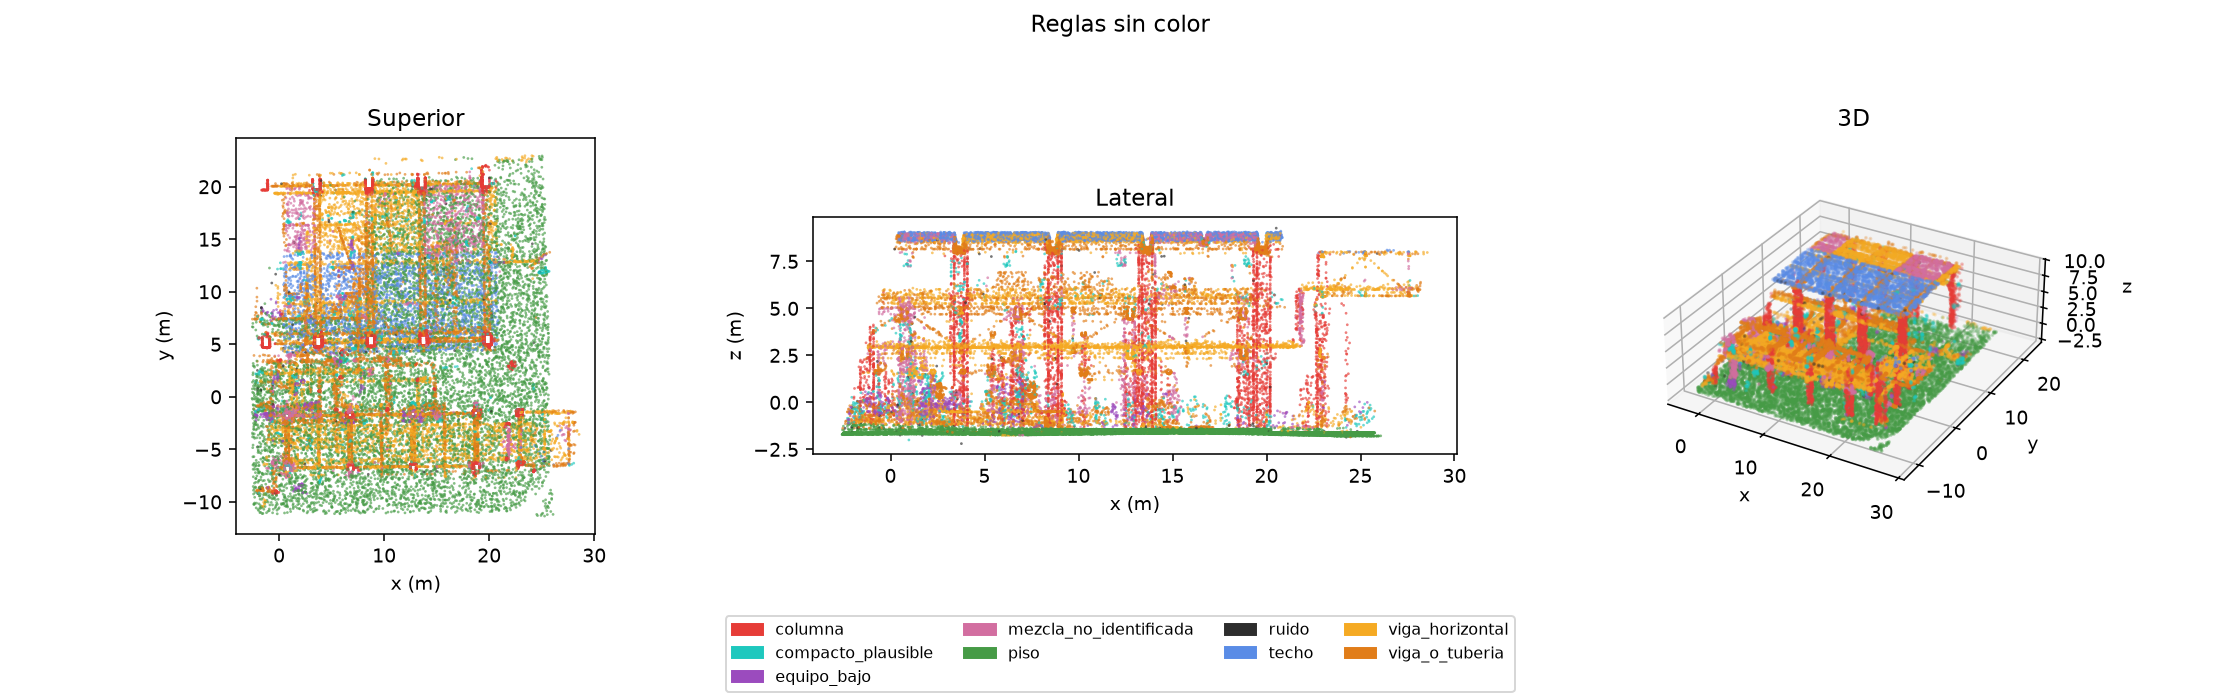

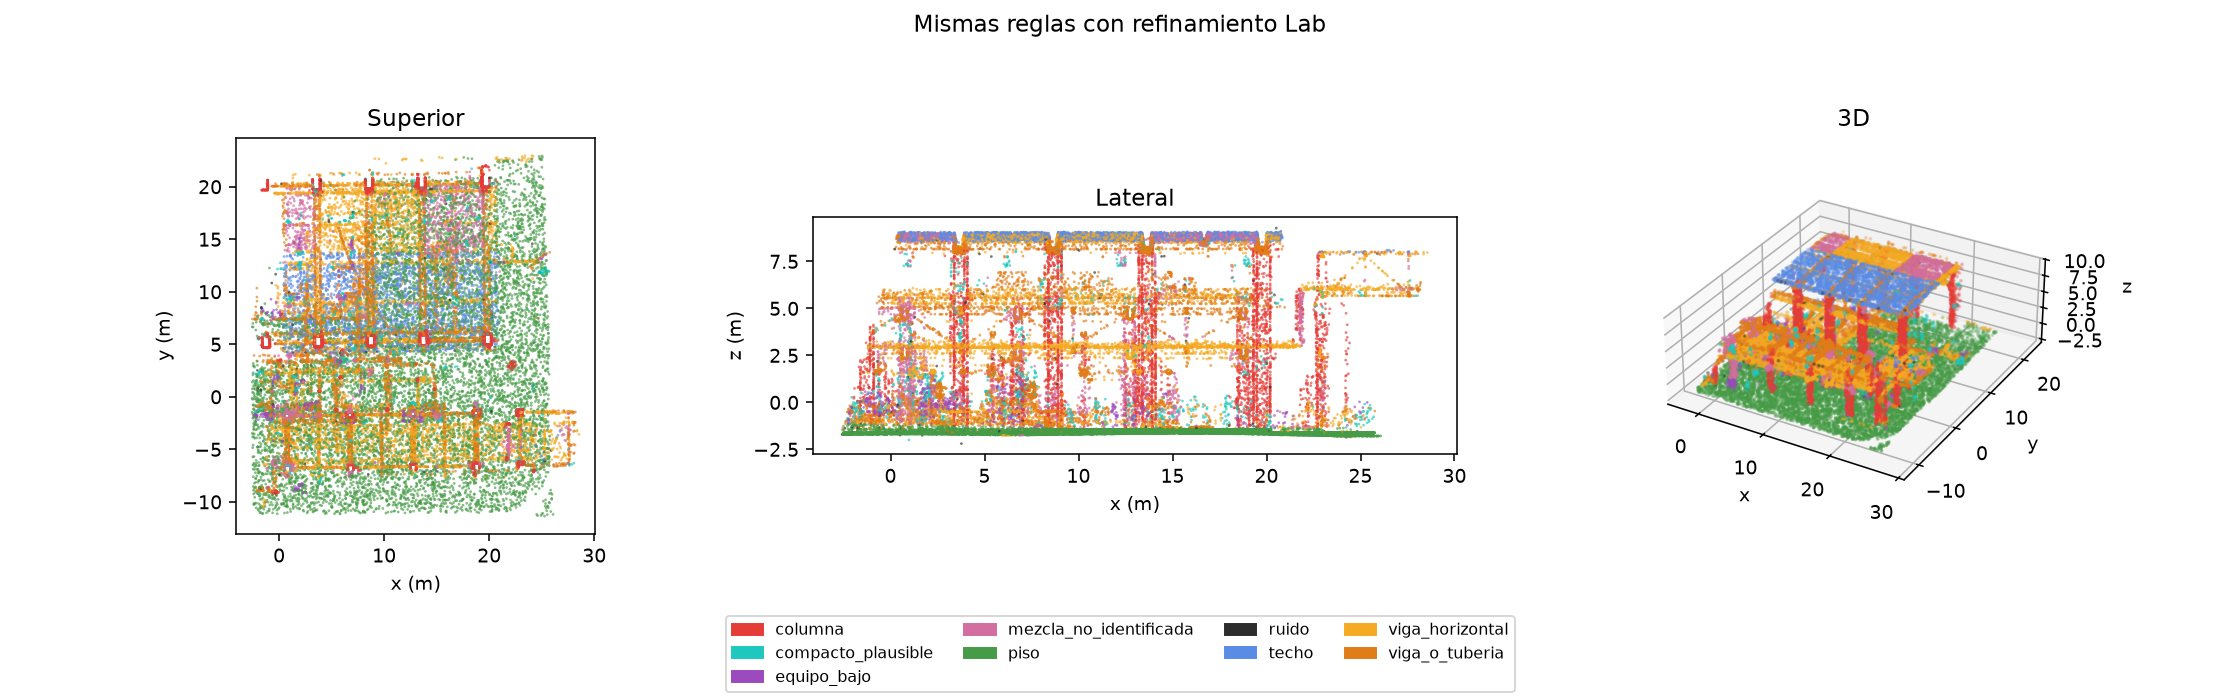

{'n_segmentos_completo': 664, 'mezcla_pct': 7.578956188172464, 'ruido_completo_pct': 0.42233827012527464, 'no_resuelto_pct': 8.001294458297739, 'n_columnas': 38, 'n_columnas_altas': 18, 'n_columnas_altas_distintas': 16, 'n_compactos': 180, 'n_divisiones_color': 3, 'segundos_notebook': 12.167621502001566}


In [2]:
params=json.loads((CACHE/'exp_config_referencia.json').read_text())
run=pipeline(cloud,cloud['xyz'],**params);desc,totals,classes=maps_and_totals(run)
# Descriptores locales de los representantes no-planos, alineados por máscara.
f=run['local_features'];idx=run['idx'];p=cloud['xyz'][idx];residual=run['residual_mask']
local_table=pd.DataFrame({key:f[key] for key in ('linealidad','planaridad','esfericidad','radio')})
local_table['orientacion']=run['orientations'];local_table['indice_original']=idx[residual]
for j,axis in enumerate('xyz'):local_table[f'e1_{axis}']=f['e1'][:,j]
local_table.to_csv(OUT/'exp_features_locales.csv',index=False)
desc.to_csv(OUT/'exp_features_instancias.csv',index=False);display(totals)
colored=pipeline(cloud,cloud['xyz'],**params,color=True);save_run('refinamiento_color',colored)
diagnostic=colored['color_diagnostic']
if diagnostic.empty:diagnostic=pd.DataFrame(columns=['id','metodo','silhouette_Lab','dispersion_ratio','min_hijo','aceptada'])
diagnostic.to_csv(OUT/'exp_color_diagnostico.csv',index=False);display(diagnostic)
color_desc,color_totals,color_classes=maps_and_totals(colored)
compare=pd.DataFrame([dict(configuracion='sin_color',**mixture_metrics(desc,totals)),dict(configuracion='con_color',**mixture_metrics(color_desc,color_totals))])
compare.to_csv(OUT/'exp_refinamiento.csv',index=False);display(compare)
view(cloud['xyz'],run['labels'],'03_antes','Reglas sin color',classes)
view(cloud['xyz'],colored['labels'],'03_despues','Mismas reglas con refinamiento Lab',color_classes)
finish('03',dict(**mixture_metrics(desc,totals),n_compactos=int((desc.clase_heuristica=='compacto_plausible').sum()),
    n_divisiones_color=int(diagnostic.aceptada.sum()) if len(diagnostic) else 0))

## Qué aprendimos / qué falló
La referencia DBSCAN con orientación tiene **7.58% de mezcla completa**, **38 candidatas a columna** y **18 fustes de ≥5 m en 16 huellas**. Son más grupos que las columnas claras de la vista: hay soportes parciales, caras y posibles falsos positivos. Por eso no tomamos el número bruto como un censo ni como exactitud.

Color aceptó **tres divisiones**: silhouette Lab de **0.3654, 0.4666 y 0.4620**, con dispersión espacial relativa **0.8983, 0.8845 y 0.8224**. La mezcla completa siguió en **7.58%**, mientras el número de segmentos subió de 664 a 667. Es una mejora local en apariencia, no una mejora demostrada en instancias. GMM quedó como diagnóstico y no sustituyó el criterio fijado.

No demostramos sección circular con estos eigenvalues: un tubo, un perfil cerrado y una pieza vista parcialmente pueden parecerse. Dejamos viga_o_tuberia cuando no hay evidencia para viga_horizontal. Los compactos plausibles tampoco son personas o vehículos identificados.